<a href="https://colab.research.google.com/github/halilcankaroglu/yzm511-midterm-mlp/blob/main/02_nested_cv.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Kurulum

In [ ]:
import os, json
os.chdir("/content")
if not os.path.exists("yzm511-midterm-mlp"):
    !git clone https://github.com/halilcankaroglu/yzm511-midterm-mlp.git
%cd /content/yzm511-midterm-mlp

from google.colab import userdata
token = userdata.get("GH_TOKEN")
!git remote set-url origin https://{token}@github.com/halilcankaroglu/yzm511-midterm-mlp.git
!git config user.name "Halil Can Karoğlu"
!git config user.email "GITHUB_EPOSTAN"

SEEDS = json.load(open("configs/seeds.json"))

Cloning into 'yzm511-midterm-mlp'...
remote: Enumerating objects: 36, done.
remote: Counting objects: 100% (36/36), done.
remote: Compressing objects: 100% (31/31), done.
remote: Total 36 (delta 6), reused 17 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (36/36), 801.14 KiB | 4.31 MiB/s, done.
Resolving deltas: 100% (6/6), done.
/content/yzm511-midterm-mlp


Manuel adaylar ve eğitim ayarları

In [ ]:
base = dict(optimizer="adamw", hidden_layers=[32], activation="relu", scaler="standard",
            lr=1e-3, weight_decay=1e-4, batch_size=64, dropout=0.0,
            clipping=False, scheduler=True)

manual = [
    dict(base, code="M1"),
    dict(base, code="M2", optimizer="adam"),
    dict(base, code="M3", optimizer="sgd"),
    dict(base, code="M4", scaler="minmax"),
    dict(base, code="M5", hidden_layers=[64, 32]),
    dict(base, code="M6", scheduler=False),
]

training = dict(max_epochs=150, es_patience=15, es_fraction=0.15,
                sched_factor=0.5, sched_patience=5, min_lr=1e-5,
                sgd_momentum=0.9, monitor="internal_val_bce",
                selection_metric="average_precision", threshold=0.5,
                outer_splits=3, inner_splits=3)

json.dump(manual, open("configs/manual_candidates.json", "w"), indent=2)
json.dump(training, open("configs/training.json", "w"), indent=2)

Random search adayları

In [ ]:
import pandas as pd
from sklearn.model_selection import ParameterSampler
from scipy.stats import loguniform

common = dict(hidden_layers=[[16], [32], [64], [64, 32], [128, 64]],
              activation=["relu", "tanh"], weight_decay=[0, 1e-5, 1e-4, 1e-3],
              batch_size=[32, 64, 128], scaler=["standard", "minmax", "robust"],
              dropout=[0.0, 0.2], clipping=[False, True])
lr_range = {"sgd": (1e-3, 1e-1), "adam": (1e-4, 1e-2), "adamw": (1e-4, 1e-2)}

rand = []
for k, opt in enumerate(["sgd", "adam", "adamw"]):
    space = dict(common, lr=loguniform(*lr_range[opt]))
    for p in ParameterSampler(space, n_iter=2, random_state=SEEDS["random_search"] + k):
        p.update(optimizer=opt, scheduler=True, lr=float(f"{p['lr']:.3g}"))
        rand.append(p)
for i, c in enumerate(rand, 1):
    c["code"] = f"R{i}"

json.dump({"search_space": {**common, "lr_log_uniform": lr_range}},
          open("configs/search_space.json", "w"), indent=2)
json.dump(rand, open("configs/random_candidates.json", "w"), indent=2)
pd.DataFrame(rand).set_index("code")

,activation,batch_size,clipping,dropout,hidden_layers,lr,scaler,weight_decay,optimizer,scheduler
code,,,,,,,,,,
R1,relu,64,False,0.0,"[64, 32]",0.004860,standard,0.00100,sgd,True
R2,relu,128,True,0.0,[32],0.001560,minmax,0.00010,sgd,True
R3,tanh,32,False,0.0,"[64, 32]",0.002760,minmax,0.00010,adam,True
R4,tanh,64,False,0.0,"[64, 32]",0.001390,minmax,0.00010,adam,True
R5,relu,32,True,0.0,[32],0.000701,standard,0.00001,adamw,True
R6,tanh,128,True,0.0,[16],0.008480,minmax,0.00100,adamw,True


In [ ]:
!git pull --rebase
!git add configs/
!git commit -m "12 aday ve arama uzayı nested CV öncesinde sabitlendi"
!git push

Already up to date.
[main a366c38] 12 aday ve arama uzayı nested CV öncesinde sabitlendi
 4 files changed, 267 insertions(+)
 create mode 100644 configs/manual_candidates.json
 create mode 100644 configs/random_candidates.json
 create mode 100644 configs/search_space.json
 create mode 100644 configs/training.json
Enumerating objects: 9, done.
Counting objects: 100% (9/9), done.
Delta compression using up to 2 threads
Compressing objects: 100% (7/7), done.
Writing objects: 100% (7/7), 1.35 KiB | 1.35 MiB/s, done.
Total 7 (delta 2), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (2/2), completed with 1 local object.
To https://github.com/halilcankaroglu/yzm511-midterm-mlp.git
   5fe51d6..a366c38  main -> main


In [ ]:
os.makedirs("src", exist_ok=True)

In [ ]:
%%writefile src/preprocessing.py
import numpy as np
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (StandardScaler, MinMaxScaler, RobustScaler,
                                   OneHotEncoder, FunctionTransformer)

NUM = ["age", "campaign", "pdays", "previous", "emp.var.rate", "cons.price.idx",
       "cons.conf.idx", "euribor3m", "nr.employed"]
CAT = ["job", "marital", "education", "default", "housing", "loan", "contact",
       "month", "day_of_week", "poutcome"]
SCALERS = {"standard": StandardScaler, "minmax": MinMaxScaler, "robust": RobustScaler}


def pdays_rule(X):
    """Sabit kural (veriden öğrenmez): 999 -> bayrak + NaN."""
    X = X.copy()
    X["pdays_kayitli"] = (X["pdays"] != 999).astype(int)
    X["pdays"] = X["pdays"].where(X["pdays"] != 999)
    return X


class PercentileClipper(BaseEstimator, TransformerMixin):
    """Eşikleri fit edildiği kümeden öğrenir, diğerlerine yalnızca uygular."""
    def __init__(self, low=1, high=99):
        self.low, self.high = low, high

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.lo_ = np.percentile(X, self.low, axis=0)
        self.hi_ = np.percentile(X, self.high, axis=0)
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lo_, self.hi_)


def build_preprocessor(scaler="standard", clipping=False):
    num_steps = [("impute", SimpleImputer(strategy="median"))]
    if clipping:
        num_steps.append(("clip", PercentileClipper()))
    num_steps.append(("scale", SCALERS[scaler]()))
    ct = ColumnTransformer([
        ("num", Pipeline(num_steps), NUM),
        ("flag", "passthrough", ["pdays_kayitli"]),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT),
    ])
    return Pipeline([("pdays", FunctionTransformer(pdays_rule)), ("ct", ct)])

Writing src/preprocessing.py


In [ ]:
import numpy as np
from src.preprocessing import build_preprocessor

df = pd.read_csv("data/bank-additional.csv", sep=";").drop(columns=["duration"])
split = pd.read_csv("results/dataset_split.csv")
dev_rows = split.loc[split["set"] == "dev", "row_index"].values

X_dev = df.iloc[dev_rows].drop(columns=["y"]).reset_index(drop=True)
y_dev = (df.iloc[dev_rows]["y"] == "yes").astype(int).values

# Deneme: ilk 2000 satırda fit, kalanında sadece transform
pre = build_preprocessor("standard", clipping=True)
A = pre.fit_transform(X_dev.iloc[:2000])
B = pre.transform(X_dev.iloc[2000:])
print(A.shape, B.shape, "NaN:", np.isnan(A).sum(), np.isnan(B).sum())
print("Öğrenilen pdays medyanı:", pre.named_steps["ct"].named_transformers_["num"].named_steps["impute"].statistics_[2])

(2000, 61) (1295, 61) NaN: 0 0
Öğrenilen pdays medyanı: 5.0


In [ ]:
!git pull --rebase
!git add src/preprocessing.py
!git commit -m "Fold-local ön işleme pipeline'ı"
!git push

Already up to date.
[main 537d55b] Fold-local ön işleme pipeline'ı
 1 file changed, 49 insertions(+)
 create mode 100644 src/preprocessing.py
Enumerating objects: 5, done.
Counting objects: 100% (5/5), done.
Delta compression using up to 2 threads
Compressing objects: 100% (3/3), done.
Writing objects: 100% (4/4), 1.23 KiB | 1.23 MiB/s, done.
Total 4 (delta 1), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (1/1), completed with 1 local object.
To https://github.com/halilcankaroglu/yzm511-midterm-mlp.git
   a366c38..537d55b  main -> main


MLP ve eğitim döngüsü

In [ ]:
%%writefile src/mlp.py
import time, copy, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from src.preprocessing import build_preprocessor

ACTS = {"relu": nn.ReLU, "tanh": nn.Tanh}


def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)


class MLP(nn.Module):
    def __init__(self, n_in, hidden, activation="relu", dropout=0.0):
        super().__init__()
        layers, prev = [], n_in
        for h in hidden:
            layers += [nn.Linear(prev, h), ACTS[activation]()]
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            prev = h
        layers.append(nn.Linear(prev, 1))          # tek logit, sigmoid yok
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(1)


def n_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def make_optimizer(model, cfg, momentum):
    p, lr, wd = model.parameters(), cfg["lr"], cfg["weight_decay"]
    if cfg["optimizer"] == "sgd":
        return torch.optim.SGD(p, lr=lr, momentum=momentum, weight_decay=wd)
    if cfg["optimizer"] == "adam":
        return torch.optim.Adam(p, lr=lr, weight_decay=wd)
    return torch.optim.AdamW(p, lr=lr, weight_decay=wd)


def fit_mlp(cfg, X, y, tr, es_seed, init_seed):
    t0 = time.time()
    # 1) Eğitim kümesini fit (%85) ve early-stop monitörü (%15) olarak ayır
    X_fit, X_es, y_fit, y_es = train_test_split(
        X, y, test_size=tr["es_fraction"], stratify=y, random_state=es_seed)

    # 2) Ön işlemeyi yalnızca fit kısmında öğren
    pre = build_preprocessor(cfg["scaler"], cfg["clipping"])
    A = torch.tensor(pre.fit_transform(X_fit), dtype=torch.float32)
    B = torch.tensor(pre.transform(X_es), dtype=torch.float32)
    ya = torch.tensor(y_fit, dtype=torch.float32)
    yb = torch.tensor(y_es, dtype=torch.float32)

    # 3) Model, optimizer, scheduler
    set_seed(init_seed)
    model = MLP(A.shape[1], cfg["hidden_layers"], cfg["activation"], cfg["dropout"])
    opt = make_optimizer(model, cfg, tr["sgd_momentum"])
    sched = (torch.optim.lr_scheduler.ReduceLROnPlateau(
                opt, mode="min", factor=tr["sched_factor"],
                patience=tr["sched_patience"], min_lr=tr["min_lr"])
             if cfg["scheduler"] else None)
    loss_fn = nn.BCEWithLogitsLoss()
    loader = DataLoader(TensorDataset(A, ya), batch_size=cfg["batch_size"], shuffle=True,
                        generator=torch.Generator().manual_seed(init_seed))

    # 4) Eğitim döngüsü + early stopping
    best, best_state, best_epoch, wait, hist = np.inf, None, 0, 0, []
    for epoch in range(1, tr["max_epochs"] + 1):
        model.train(); total = 0.0
        for xb, yb_ in loader:
            opt.zero_grad()
            loss = loss_fn(model(xb), yb_)
            loss.backward(); opt.step()
            total += loss.item() * len(xb)
        model.eval()
        with torch.no_grad():
            val = loss_fn(model(B), yb).item()
        hist.append(dict(epoch=epoch, train_loss=total / len(A), val_loss=val,
                         lr=opt.param_groups[0]["lr"]))
        if sched:
            sched.step(val)
        if val < best - 1e-6:
            best, best_epoch, wait = val, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= tr["es_patience"]:
                break
    model.load_state_dict(best_state)              # en iyi ağırlıklara dön
    return dict(model=model, pre=pre, history=pd.DataFrame(hist),
                best_epoch=best_epoch, epochs_run=epoch,
                seconds=time.time() - t0, n_params=n_params(model))


def predict_proba(res, X):
    res["model"].eval()
    with torch.no_grad():
        Z = torch.tensor(res["pre"].transform(X), dtype=torch.float32)
        return torch.sigmoid(res["model"](Z)).numpy()

Writing src/mlp.py


best_epoch=9 | epochs_run=24 | 7.5 sn | params=2049 | AP=0.406


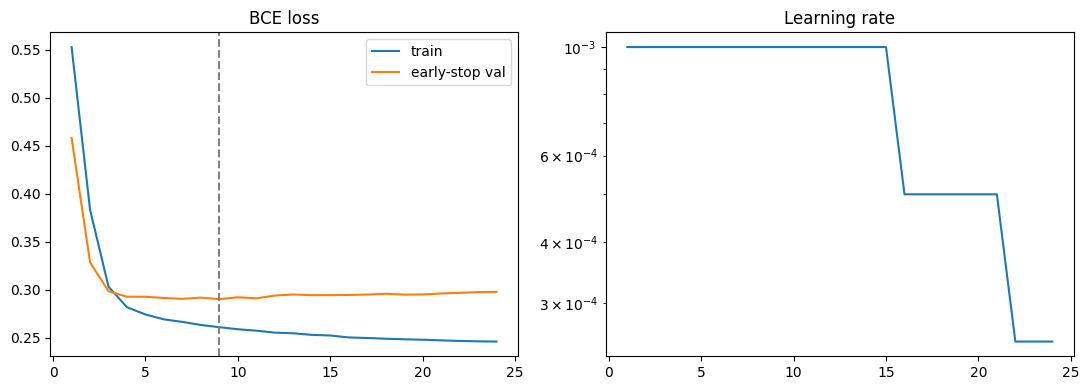

In [ ]:
import importlib, src.mlp as mlp
importlib.reload(mlp)
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import average_precision_score
import matplotlib.pyplot as plt

training = json.load(open("configs/training.json"))
manual = json.load(open("configs/manual_candidates.json"))

tr_idx, va_idx = next(StratifiedKFold(3, shuffle=True, random_state=SEEDS["inner_cv"]).split(X_dev, y_dev))
res = mlp.fit_mlp(manual[0], X_dev.iloc[tr_idx], y_dev[tr_idx], training,
                  es_seed=SEEDS["early_stop"], init_seed=SEEDS["init"][0])
ap = average_precision_score(y_dev[va_idx], mlp.predict_proba(res, X_dev.iloc[va_idx]))
print(f"best_epoch={res['best_epoch']} | epochs_run={res['epochs_run']} | "
      f"{res['seconds']:.1f} sn | params={res['n_params']} | AP={ap:.3f}")

h = res["history"]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(h.epoch, h.train_loss, label="train"); ax[0].plot(h.epoch, h.val_loss, label="early-stop val")
ax[0].axvline(res["best_epoch"], ls="--", c="gray"); ax[0].legend(); ax[0].set_title("BCE loss")
ax[1].plot(h.epoch, h.lr); ax[1].set_yscale("log"); ax[1].set_title("Learning rate")
plt.tight_layout(); plt.show()

In [ ]:
!git pull --rebase
!git add src/mlp.py
!git commit -m "PyTorch MLP, early stopping ve ReduceLROnPlateau"
!git push

Already up to date.
[main 7e185ea] PyTorch MLP, early stopping ve ReduceLROnPlateau
 1 file changed, 104 insertions(+)
 create mode 100644 src/mlp.py
Enumerating objects: 6, done.
Counting objects: 100% (6/6), done.
Delta compression using up to 2 threads
Compressing objects: 100% (4/4), done.
Writing objects: 100% (4/4), 1.99 KiB | 1.99 MiB/s, done.
Total 4 (delta 1), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (1/1), completed with 1 local object.
To https://github.com/halilcankaroglu/yzm511-midterm-mlp.git
   537d55b..7e185ea  main -> main


Nested CV

Metrikler

In [ ]:
%%writefile src/metrics.py
from sklearn.metrics import (average_precision_score, roc_auc_score, accuracy_score,
                             precision_score, recall_score, f1_score,
                             balanced_accuracy_score, confusion_matrix)


def compute_metrics(y, p, thr=0.5):
    yhat = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yhat, labels=[0, 1]).ravel()
    return dict(
        AP=average_precision_score(y, p), ROC_AUC=roc_auc_score(y, p),
        Accuracy=accuracy_score(y, yhat),
        Precision=precision_score(y, yhat, zero_division=0),
        Sensitivity=recall_score(y, yhat, zero_division=0),
        Specificity=tn / (tn + fp), F1=f1_score(y, yhat, zero_division=0),
        Balanced_Acc=balanced_accuracy_score(y, yhat))

Overwriting src/metrics.py


iç CV ve arama

In [ ]:
%%writefile src/nested_cv.py
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import average_precision_score
from src.mlp import fit_mlp, predict_proba


def inner_cv(cfg, X, y, tr, seeds, tag):
    skf = StratifiedKFold(tr["inner_splits"], shuffle=True, random_state=seeds["inner_cv"])
    aps, eps, secs, logs = [], [], [], []
    for j, (a, b) in enumerate(skf.split(X, y)):
        res = fit_mlp(cfg, X.iloc[a], y[a], tr, seeds["early_stop"], seeds["init"][0])
        aps.append(average_precision_score(y[b], predict_proba(res, X.iloc[b])))
        eps.append(res["best_epoch"]); secs.append(res["seconds"])
        logs.append(res["history"].assign(**tag, code=cfg["code"], inner=j,
                                           best_epoch=res["best_epoch"],
                                           epochs_run=res["epochs_run"]))
    row = dict(**tag, code=cfg["code"], mean_ap=np.mean(aps), sd_ap=np.std(aps, ddof=1),
               ap_folds=np.round(aps, 4).tolist(), best_epochs=eps, seconds=sum(secs),
               **{k: v for k, v in cfg.items() if k != "code"})
    return row, pd.concat(logs)


def run_search(cands, X, y, tr, seeds, tag):
    out = [inner_cv(c, X, y, tr, seeds, tag) for c in cands]
    rows = pd.DataFrame([r for r, _ in out])
    best = rows.loc[rows["mean_ap"].idxmax(), "code"]   # eşitlikte listede önce gelen
    return rows, pd.concat([l for _, l in out]), best

Overwriting src/nested_cv.py


In [ ]:
!git pull --rebase
!git add src/
!git commit -m "Metrikler ve iç CV arama modülü"
!git push

Already up to date.
[main 8be9040] Metrikler ve iç CV arama modülü
 4 files changed, 43 insertions(+)
 create mode 100644 src/__pycache__/mlp.cpython-313.pyc
 create mode 100644 src/__pycache__/preprocessing.cpython-313.pyc
 create mode 100644 src/metrics.py
 create mode 100644 src/nested_cv.py
Enumerating objects: 10, done.
Counting objects: 100% (10/10), done.
Delta compression using up to 2 threads
Compressing objects: 100% (8/8), done.
Writing objects: 100% (8/8), 7.68 KiB | 7.68 MiB/s, done.
Total 8 (delta 1), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (1/1), completed with 1 local object.
To https://github.com/halilcankaroglu/yzm511-midterm-mlp.git
   7e185ea..8be9040  main -> main


Dış döngü

In [ ]:
import importlib, src.mlp, src.nested_cv, src.metrics
for m in (src.mlp, src.nested_cv, src.metrics): importlib.reload(m)
from src.nested_cv import run_search
from src.metrics import compute_metrics
from src.mlp import fit_mlp, predict_proba
from src.preprocessing import build_preprocessor
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

rand = json.load(open("configs/random_candidates.json"))
cands = {"manual": {c["code"]: c for c in manual}, "random": {c["code"]: c for c in rand}}
outer = StratifiedKFold(training["outer_splits"], shuffle=True, random_state=SEEDS["outer_cv"])
search_rows, log_rows, outer_rows = [], [], []

for k, (otr, oev) in enumerate(outer.split(X_dev, y_dev)):
    Xtr, ytr, Xev, yev = X_dev.iloc[otr], y_dev[otr], X_dev.iloc[oev], y_dev[oev]

    for method, cd in cands.items():
        rows, logs, best = run_search(list(cd.values()), Xtr, ytr, training, SEEDS,
                                      dict(outer=k, method=method))
        search_rows.append(rows); log_rows.append(logs)
        res = fit_mlp(cd[best], Xtr, ytr, training, SEEDS["early_stop"], SEEDS["init"][0])
        outer_rows.append(dict(outer=k, model=f"MLP-{method}", selected=best,
                               **compute_metrics(yev, predict_proba(res, Xev))))
        print(f"outer {k} | {method}: seçilen {best} | iç AP {rows.mean_ap.max():.3f} "
              f"| dış AP {outer_rows[-1]['AP']:.3f}")

    for name, est in [("Dummy", DummyClassifier(strategy="most_frequent")),
                      ("LogReg", Pipeline([("pre", build_preprocessor("standard")),
                                           ("clf", LogisticRegression(max_iter=2000))]))]:
        est.fit(Xtr, ytr)
        outer_rows.append(dict(outer=k, model=name, selected="-",
                               **compute_metrics(yev, est.predict_proba(Xev)[:, 1])))

    # Her dış kattan sonra ara kayıt
    s = pd.concat(search_rows)
    s[s.method == "manual"].to_csv("results/manual_search_results.csv", index=False)
    s[s.method == "random"].to_csv("results/random_search_results.csv", index=False)
    pd.concat(log_rows).to_csv("results/training_logs.csv", index=False)
    pd.DataFrame(outer_rows).to_csv("results/outer_cv_results.csv", index=False)

outer 0 | manual: seçilen M4 | iç AP 0.436 | dış AP 0.406
outer 0 | random: seçilen R4 | iç AP 0.434 | dış AP 0.394
outer 1 | manual: seçilen M2 | iç AP 0.412 | dış AP 0.456
outer 1 | random: seçilen R4 | iç AP 0.403 | dış AP 0.421
outer 2 | manual: seçilen M4 | iç AP 0.412 | dış AP 0.398
outer 2 | random: seçilen R6 | iç AP 0.406 | dış AP 0.368


In [ ]:
o = pd.read_csv("results/outer_cv_results.csv")
m = ["AP", "ROC_AUC", "F1", "Sensitivity", "Specificity", "Balanced_Acc"]
agg = o.groupby("model")[m].agg(["mean", "std"])          # std: örnek SD (ddof=1)
summary = pd.DataFrame({c: agg[c]["mean"].map("{:.3f}".format) + " ± " +
                           agg[c]["std"].map("{:.3f}".format) for c in m})
summary.to_csv("results/outer_cv_summary.csv")
display(summary)

# Adayların iç CV performansı: üç dış kat boyunca ortalama
s = pd.concat([pd.read_csv("results/manual_search_results.csv"),
               pd.read_csv("results/random_search_results.csv")])
cand = (s.groupby(["method", "code"])
          .agg(mean_ap=("mean_ap", "mean"), sd_between_outer=("mean_ap", "std"),
               seconds=("seconds", "mean"))
          .round(4).sort_values(["method", "mean_ap"], ascending=[True, False]))
display(cand)

# H2: optimizer'ların yakınsama hızı
logs = pd.read_csv("results/training_logs.csv")
ep = (logs.drop_duplicates(["outer", "method", "code", "inner"])
          .groupby("code")[["best_epoch", "epochs_run"]].mean().round(1))
display(ep.loc[["M1", "M2", "M3"]])

,AP,ROC_AUC,F1,Sensitivity,Specificity,Balanced_Acc
model,,,,,,
Dummy,0.110 ± 0.000,0.500 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,1.000 ± 0.000,0.500 ± 0.000
LogReg,0.415 ± 0.023,0.762 ± 0.026,0.330 ± 0.039,0.227 ± 0.035,0.982 ± 0.002,0.605 ± 0.017
MLP-manual,0.420 ± 0.032,0.763 ± 0.019,0.293 ± 0.051,0.197 ± 0.048,0.983 ± 0.005,0.590 ± 0.021
MLP-random,0.394 ± 0.026,0.754 ± 0.020,0.291 ± 0.060,0.197 ± 0.048,0.982 ± 0.003,0.589 ± 0.024


mean_ap  sd_between_outer  seconds
method code                                    
manual M4     0.4143            0.0208   1.8530
       M2     0.4091            0.0183   1.4328
       M1     0.4090            0.0183   1.7046
       M6     0.4090            0.0183   1.3753
       M5     0.4026            0.0131   1.4948
       M3     0.4021            0.0167   6.6569
random R4     0.4134            0.0177   1.3917
       R6     0.4086            0.0097   0.8929
       R3     0.4078            0.0201   1.9193
       R2     0.4073            0.0202   5.0202
       R5     0.4041            0.0224   2.5964
       R1     0.3898            0.0279   2.7029

,best_epoch,epochs_run
code,,
M1,10.3,25.3
M2,10.0,25.0
M3,112.4,124.3


In [ ]:
!git pull --rebase
!git add results/
!git commit -m "Nested CV sonuçları (3x3, manuel + otomatik + referanslar)"
!git push

Already up to date.
[main 1c01022] Nested CV sonuçları (3x3, manuel + otomatik + referanslar)
 5 files changed, 4891 insertions(+)
 create mode 100644 results/manual_search_results.csv
 create mode 100644 results/outer_cv_results.csv
 create mode 100644 results/outer_cv_summary.csv
 create mode 100644 results/random_search_results.csv
 create mode 100644 results/training_logs.csv
Enumerating objects: 10, done.
Counting objects: 100% (10/10), done.
Delta compression using up to 2 threads
Compressing objects: 100% (8/8), done.
Writing objects: 100% (8/8), 107.01 KiB | 2.49 MiB/s, done.
Total 8 (delta 1), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (1/1), completed with 1 local object.
To https://github.com/halilcankaroglu/yzm511-midterm-mlp.git
   8be9040..1c01022  main -> main


SGD kontrolü ve Şekil 5

      outer  method code  inner  best_epoch
909       0  random   R2      0         150
1059      0  random   R2      1         150
1209      0  random   R2      2         150
1783      1  manual   M3      0         148
2036      1  manual   M3      2         150
2649      1  random   R2      0         150
2799      1  random   R2      1         150
2949      1  random   R2      2         150
4160      2  random   R2      0         150
4446      2  random   R2      2         150


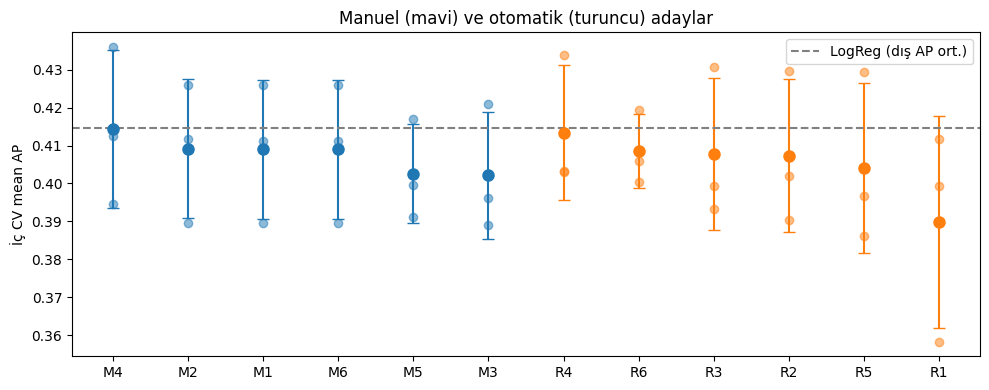

In [ ]:
# 150 epoch sınırına takılan eğitim var mı? (raporlanması zorunlu)
runs = logs.drop_duplicates(["outer", "method", "code", "inner"])
print(runs[runs.epochs_run >= training["max_epochs"]][["outer", "method", "code", "inner", "best_epoch"]])

# Şekil 5: adayların iç CV AP'si (her nokta bir dış kat)
fig, ax = plt.subplots(figsize=(10, 4))
order = list(cand.loc["manual"].index) + list(cand.loc["random"].index)
for i, code in enumerate(order):
    v = s[s.code == code]["mean_ap"]
    color = "tab:blue" if code.startswith("M") else "tab:orange"
    ax.scatter([i] * len(v), v, color=color, alpha=.5)
    ax.errorbar(i, v.mean(), yerr=v.std(), fmt="o", color=color, capsize=4, ms=8)
ax.axhline(o[o.model == "LogReg"]["AP"].mean(), ls="--", c="gray", label="LogReg (dış AP ort.)")
ax.set_xticks(range(len(order))); ax.set_xticklabels(order)
ax.set_ylabel("İç CV mean AP"); ax.set_title("Manuel (mavi) ve otomatik (turuncu) adaylar")
ax.legend(); plt.tight_layout(); plt.savefig("figures/search_comparison.png", dpi=150); plt.show()

In [ ]:
!git pull --rebase
!git add figures/search_comparison.png
!git commit -m "Arama karşılaştırma grafiği"
!git push

Already up to date.
[main 400fcdb] Arama karşılaştırma grafiği
 1 file changed, 0 insertions(+), 0 deletions(-)
 create mode 100644 figures/search_comparison.png
Enumerating objects: 6, done.
Counting objects: 100% (6/6), done.
Delta compression using up to 2 threads
Compressing objects: 100% (4/4), done.
Writing objects: 100% (4/4), 47.49 KiB | 7.91 MiB/s, done.
Total 4 (delta 2), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (2/2), completed with 2 local objects.
To https://github.com/halilcankaroglu/yzm511-midterm-mlp.git
   1c01022..400fcdb  main -> main
